# Project — modelling notebook

**Author:** Alex Ramirez Duran · **Dataset:** [Online Retail II](https://doi.org/10.24432/C5CG6D) · **Prepared:** 12 November 2026

Unit 17: Retail Sales Intelligence and Demand Forecasting. This notebook continues the approved project brief. The lecturer awarded the brief 99/100 (student-reported feedback); that mark is context, not evidence of predictive performance.

## 0. Executive summary

1. Forecast next-week recorded sales for fifty established UK products, supporting weekly inventory review.
2. The selected trained model is temporally tuned histogram gradient boosting.
3. Test WAPE is 64.98%, versus 71.81% for last week: a 9.50% relative improvement; the four-week mean is better at 61.20%.
4. Retain the four-week mean as the operational reference; do not automate purchasing with the trained model.
5. Historical sales omit stock availability and lost demand; the short-horizon uncertainty interval includes no improvement.

## Setup

The course environment supplies pandas, NumPy, scikit-learn, Plotly and PyArrow; joblib arrives with scikit-learn. No extra runtime package is required. The committed weekly aggregates make loading fast and independent of a network connection. `retail_features.py` must stay beside the saved model: it supplies stateless feature functions, while every learned transformation belongs inside the pipeline (scikit-learn developers, n.d.-a).

In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform
START = time.perf_counter()
import numpy as np
import pandas as pd
import plotly, plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import sklearn, joblib
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, make_scorer
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

SEED = 17
np.random.seed(SEED)
threadpool_limits(limits=2)
BASE = Path('.') if Path('data/weekly-sales.parquet').exists() else Path('project')
assert (BASE/'data/weekly-sales.parquet').exists(), 'Run from the repository root or project/ folder'
sys.path.insert(0, str(BASE.resolve()))
from retail_features import LAGS, NUMERIC, make_features, identity, nonnegative
RESULTS = BASE/'results'
RESULTS.mkdir(exist_ok=True)
pio.renderers.default = 'plotly_mimetype'
px.defaults.template = 'plotly_white'

def show(fig, name):
    # Plotly MIME for GitHub and a standalone HTML fallback with bundled Plotly JS.
    fig.update_layout(font=dict(size=13), margin=dict(l=60,r=25,t=70,b=55))
    fig.write_html(RESULTS/(name+'.html'), include_plotlyjs=True, full_html=True)
    fig.show()

def scores(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    assert np.isfinite(predicted).all() and (predicted>=0).all()
    denominator = actual.sum()
    return {'MAE_units':mean_absolute_error(actual,predicted),
            'RMSE_units':np.sqrt(mean_squared_error(actual,predicted)),
            'WAPE_pct':100*np.abs(actual-predicted).sum()/denominator if denominator else np.nan,
            'bias_units':float(np.mean(predicted-actual))}

## 1. From the brief to an ML task

| Question | Answer |
|---|---|
| Decision | Which established UK products need closer weekly purchasing review? |
| Task | Nonnegative regression of recorded sales, not stock requirements. |
| Target | Sum of eligible positive quantities for one SKU during the coming Monday–Sunday week. |
| Grain | One UK product × forecast week. |
| Moment and horizon | Monday, after the previous week closes; seven days ahead. |
| Available information | Product identifier, forecast date, previous thirteen weekly unit totals. |
| Today's rule | Repeat the previous week's units. |
| Metric | WAPE for portfolio comparison, with MAE in units and RMSE for large errors. |
| Business translation | Fewer absolute unit errors in a purchasing review list; no proven stockout or profit saving. |

**Changes since the brief:** limit modelling to fifty products selected by UK units in the first twenty-six complete weeks. This uses no future rankings and bounds runtime. Country comparison remains in exploration; country is constant in the forecast. The target and one-week horizon stay unchanged. The 5% relative WAPE improvement is a proposed acceptance threshold, not a promised outcome. H2's shared-product cohort is exploratory and must not determine model selection.

**What this means for the stakeholder.** The forecasts cover established UK products only. New products and international orders require a separate fallback; the manager still needs inventory and lead-time information before placing orders.

## 2. Data and quality

Chen (2012) supplies UK retailer invoice lines from December 2009 to December 2011 under CC BY 4.0. The original workbook has 1,067,371 lines and eight fields. The preparation script, `../src/prepare_model_data.py`, preserves the source and records sequential exclusions in the committed audit. The notebook reads anonymous SKU–market–week aggregates; the full cleaning is reproducible from the original workbook.

Exact duplicates are removed once as a conservative proposal; identical lines could be legitimate, so their removed units and value are disclosed rather than presented as certain errors. Cancelled invoices, nonpositive quantities/prices and nonstandard product codes are excluded. The merchandise regex is a transparent proxy, not a verified category taxonomy. Customer IDs and descriptions are neither required nor imputed. Large positive orders remain because wholesale activity can be real. Incomplete boundary weeks are excluded to avoid artificially low totals.

In [2]:
audit = json.loads((BASE/'data/quality-audit.json').read_text())
source_file = BASE/'data/weekly-sales.parquet'
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == audit['weekly_file_sha256']
weekly = pd.read_parquet(source_file)
weekly['week_start'] = pd.to_datetime(weekly.week_start)
assert not weekly.duplicated(['StockCode','market','week_start']).any()
assert (weekly.units>0).all()
display(pd.DataFrame(audit['audit']))
display(pd.Series({k:audit[k] for k in ['source_rows','complete_week_start','complete_week_end',
    'retained_transaction_lines','aggregate_rows','missing_customer_ids_retained',
    'missing_descriptions_retained','large_positive_lines_above_1000_units_retained',
    'positive_duplicate_units_removed','positive_duplicate_value_removed_gbp']}, name='Measured audit'))
weeks = pd.date_range(audit['complete_week_start'],audit['complete_week_end'],freq='W-MON')
selection_end = weeks[25]
uk = weekly[weekly.market.eq('UK')].copy()
rank = uk[uk.week_start<=selection_end].groupby('StockCode').units.sum().sort_values(ascending=False)
cohort = sorted(rank.head(50).index)
idx = pd.MultiIndex.from_product([cohort,weeks],names=['StockCode','week_start'])
panel = uk.groupby(['StockCode','week_start']).units.sum().reindex(idx,fill_value=0).rename('units').reset_index()
panel = panel.sort_values(['StockCode','week_start']).reset_index(drop=True)
for lag in range(1,14):
    panel[f'lag_{lag}'] = panel.groupby('StockCode',sort=False).units.shift(lag)
model_data = panel[panel.week_start>selection_end].dropna(subset=LAGS).sort_values(['week_start','StockCode']).reset_index(drop=True)
model_weeks = np.sort(model_data.week_start.unique())
TEST_WEEKS, VAL_WEEKS = 14, 12
val_start, test_start = pd.Timestamp(model_weeks[-(TEST_WEEKS+VAL_WEEKS)]), pd.Timestamp(model_weeks[-TEST_WEEKS])
train = model_data[model_data.week_start<val_start].copy()
valid = model_data[model_data.week_start.between(val_start,test_start,inclusive='left')].copy()
# Targets from test weeks are not inspected for charts, model choice or tuning.
test = model_data[model_data.week_start>=test_start].copy()
assert selection_end < train.week_start.min() < train.week_start.max() < valid.week_start.min() < valid.week_start.max() < test.week_start.min()
RAW_FEATURES = ['StockCode','week_start']+LAGS
X_train,y_train = train[RAW_FEATURES],train.units
X_valid,y_valid = valid[RAW_FEATURES],valid.units
print('Cohort fixed using data through:',selection_end.date())
display(pd.DataFrame([{'split':n,'first_week':f.week_start.min(),'last_week':f.week_start.max(),'rows':len(f),'weeks':f.week_start.nunique()}
                     for n,f in [('Train',train),('Validation',valid),('Test (sealed)',test)]]))

,step,before,removed,after
0,Exact duplicate invoice lines: retain first,1067371,34335,1033036
1,Valid date and country,1033036,0,1033036
2,Separate credit/cancellation invoices,1033036,19104,1013932
3,Positive units and prices only,1013932,6019,1007913
4,Merchandise-code proxy: five digits and option...,1007913,5908,1002005
5,Complete Monday-Sunday weeks only,1002005,31096,970909


source_rows                                          1067371
complete_week_start                               2009-12-07
complete_week_end                                 2011-11-28
retained_transaction_lines                            970909
aggregate_rows                                        236901
missing_customer_ids_retained                         217261
missing_descriptions_retained                              0
large_positive_lines_above_1000_units_retained           290
positive_duplicate_units_removed                    215157.0
positive_duplicate_value_removed_gbp               496334.12
Name: Measured audit, dtype: object

Cohort fixed using data through: 2010-05-31


,split,first_week,last_week,rows,weeks
0,Train,2010-06-07,2011-05-30,2600,52
1,Validation,2011-06-06,2011-08-22,600,12
2,Test (sealed),2011-08-29,2011-11-28,700,14


**What this means for the stakeholder.** These figures describe positive recorded merchandise sales. Credits and shipping adjustments require separate reconciliation; missing customer IDs do not erase otherwise usable sales.

## 3. What the exploration showed

The four charts use pre-test information only: the target distribution, weekly UK totals, product concentration and calendar behaviour. Zero weeks are retained for the fixed known cohort, including possible discontinued products. A zero means no recorded eligible sale, not proof of product availability.

H1 uses full calendar quarters observed before test, with both all-market and UK-only shares. H2 needs November 2011, which overlaps the sealed test; its final descriptive check is deferred until section 8, after models are frozen. H3 is also resolved there. These are descriptive checks rather than causal or significance claims.

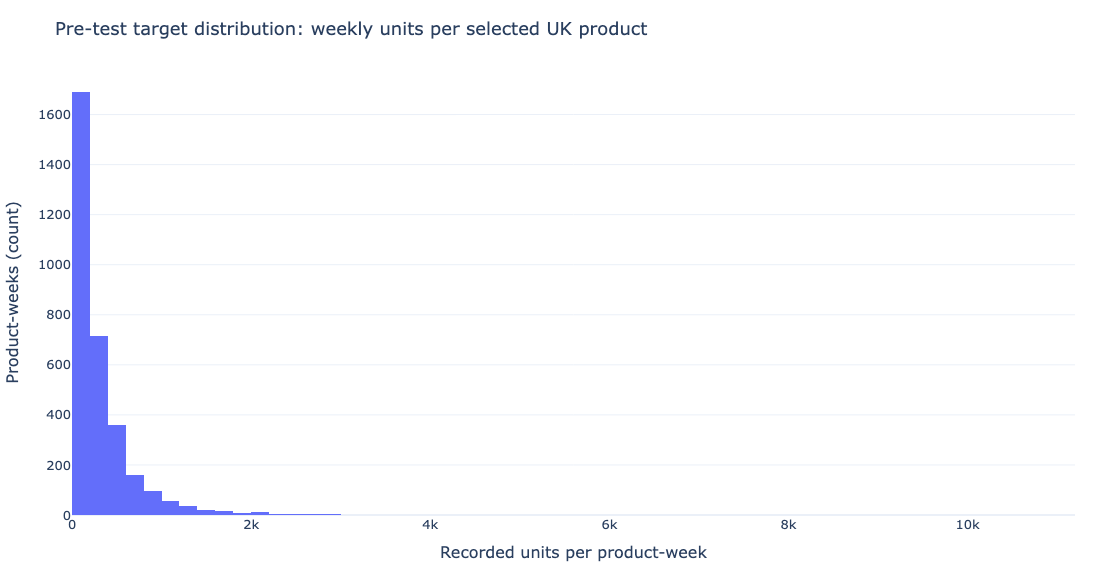

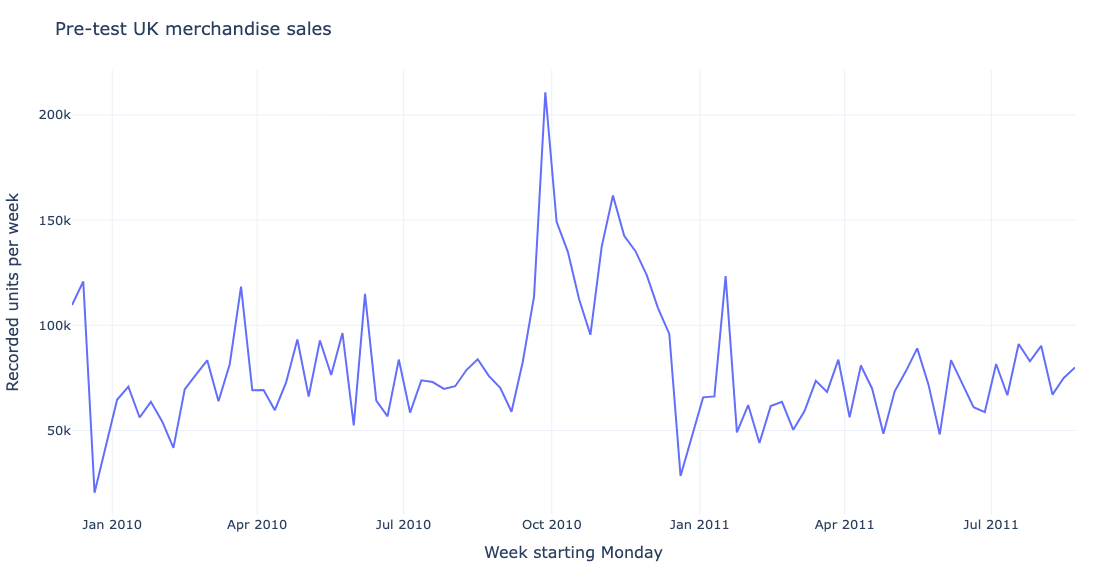

,market,quarter,top20_share_pct,sku_count
0,All,2010Q1,81.731451,3238
1,All,2010Q2,81.657821,3112
2,All,2010Q3,80.270032,3150
3,All,2010Q4,79.379383,3204
4,All,2011Q1,78.568275,2899
5,All,2011Q2,79.735085,3017
6,UK,2010Q1,78.884062,3219
7,UK,2010Q2,81.570769,3091
8,UK,2010Q3,79.812071,3124
9,UK,2010Q4,80.267199,3197


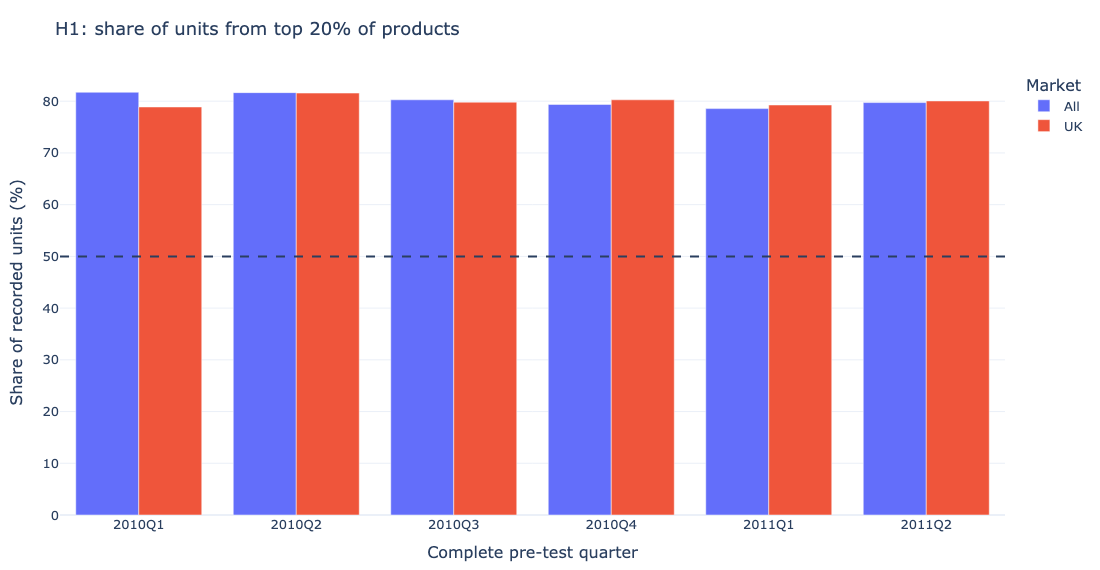

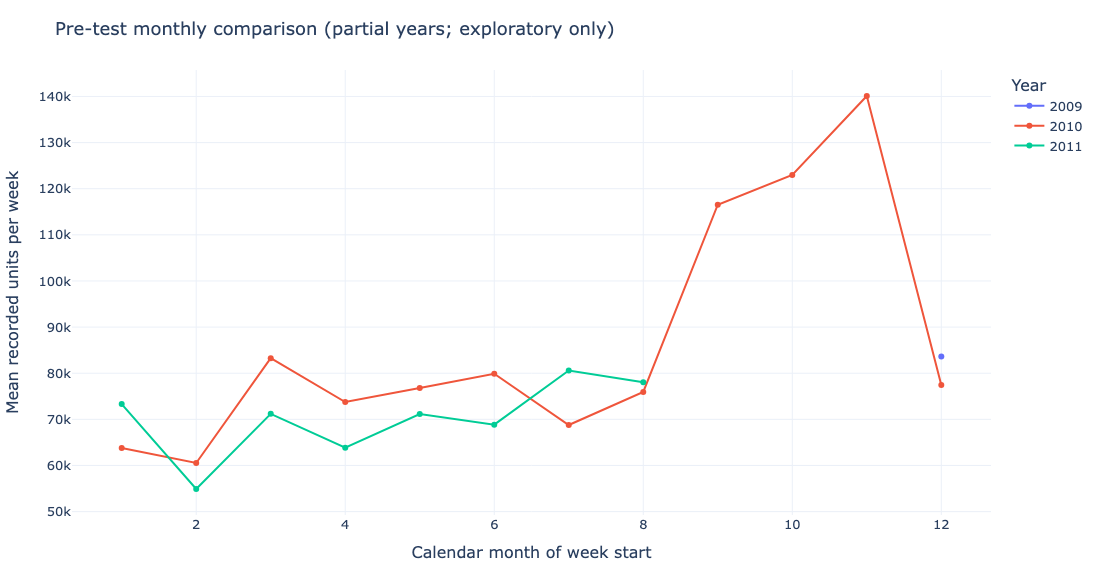

,Hypothesis,Status,Evidence
0,H1: top 20% contribute >50%,supported,Pre-test quarter shares: 78.6%–81.7%; both mar...
1,H2: November ratio >1.10 in both years,not testable yet,November 2011 belongs to final holdout; no two...
2,H3: WAPE falls at least 5% vs previous week,not testable yet,Final evaluation deferred to section 8


In [3]:
development = model_data[model_data.week_start<test_start]
show(px.histogram(development,x='units',nbins=60,title='Pre-test target distribution: weekly units per selected UK product',
                  labels={'units':'Recorded units per product-week'}).update_yaxes(title='Product-weeks (count)'), 'target-distribution')
total_pre = uk[uk.week_start<test_start].groupby('week_start',as_index=False).units.sum()
show(px.line(total_pre,x='week_start',y='units',title='Pre-test UK merchandise sales',labels={'week_start':'Week starting Monday','units':'Recorded units per week'}),'weekly-trend')
quarter_rows=[]
for market in ['All','UK']:
    z=weekly[(weekly.week_start<test_start)&(weekly.market.eq('UK') if market=='UK' else True)].copy()
    z['quarter']=(z.week_start+pd.Timedelta(days=3)).dt.to_period('Q')
    for q,g in z.groupby('quarter'):
        # Only quarters fully covered by complete weekly observations, using Thursday attribution.
        if q.start_time < weeks.min() or q.end_time.normalize()+pd.Timedelta(days=7)>=test_start: continue
        volume=g.groupby('StockCode').units.sum().sort_values(ascending=False)
        top_count=int(np.ceil(.2*len(volume)))
        quarter_rows.append({'market':market,'quarter':str(q),'top20_share_pct':100*volume.head(top_count).sum()/volume.sum(),'sku_count':len(volume)})
h1=pd.DataFrame(quarter_rows)
display(h1)
show(px.bar(h1,x='quarter',y='top20_share_pct',color='market',barmode='group',title='H1: share of units from top 20% of products',
            labels={'quarter':'Complete pre-test quarter','top20_share_pct':'Share of recorded units (%)','market':'Market'}).add_hline(y=50,line_dash='dash'),'concentration')
season=total_pre.copy();season['month']=season.week_start.dt.month;season['year']=season.week_start.dt.year.astype(str)
season=season.groupby(['year','month'],as_index=False).units.mean()
show(px.line(season,x='month',y='units',color='year',markers=True,title='Pre-test monthly comparison (partial years; exploratory only)',
             labels={'month':'Calendar month of week start','units':'Mean recorded units per week','year':'Year'}),'seasonality')
h1_status='supported' if h1.top20_share_pct.gt(50).all() else 'refuted'
hypotheses=pd.DataFrame([
 {'Hypothesis':'H1: top 20% contribute >50%','Status':h1_status,'Evidence':f'Pre-test quarter shares: {h1.top20_share_pct.min():.1f}%–{h1.top20_share_pct.max():.1f}%; both markets'},
 {'Hypothesis':'H2: November ratio >1.10 in both years','Status':'not testable yet','Evidence':'November 2011 belongs to final holdout; no two-year claim made'},
 {'Hypothesis':'H3: WAPE falls at least 5% vs previous week','Status':'not testable yet','Evidence':'Final evaluation deferred to section 8'}])
display(hypotheses)

**What this means for the stakeholder.** Concentration can prioritise attention, but the model must also handle quiet weeks and occasional bulk orders. We do not assume that an attractive seasonal chart establishes reliable annual recurrence.

## 4. Features

The saved pipeline accepts one as-of row: product, forecast Monday and thirteen historical weekly totals. It derives rolling and calendar features itself before encoding and scaling. The upstream service must aggregate closed sales weeks; the artifact does not accept arbitrary invoice rows. No current-week quantity, realised price, customer identifier, future ranking or stockout flag is allowed.

| Feature | Construction and reason | Available on Monday? |
|---|---|---|
| SKU | One-hot product identity; persistent product differences | Yes, fixed initial cohort |
| Lags 1, 2, 4, 13 | Earlier closed-week units; recent level and persistence | Yes |
| Mean 4 and 13 | Arithmetic means of shifted units; smooth volatility | Yes |
| Standard deviation 4 | Population spread of four lags; volatility | Yes |
| Zero share 13 | Proportion of past thirteen weeks without sales; intermittency | Yes |
| Week sine/cosine | Known forecast ISO week; smooth calendar cycle | Yes |
| Trend | Weeks since fixed origin; gradual changes | Yes |

Imputation, scaling and encoding are fitted only on each training fold. No learned full-table statistics enter the inputs. Ablations later test whether rolling summaries or calendar features actually help.

In [4]:
display(make_features(X_train.head(3)))
assert (X_train[LAGS]>=0).all().all()
# Verify the newest lag against the prior week's observed units for a sample row.
r=X_train.iloc[0]
prior=panel[(panel.StockCode==r.StockCode)&(panel.week_start==r.week_start-pd.Timedelta(days=7))].units.iloc[0]
assert r.lag_1==prior

def build_pipeline(kind='linear', mode='full', **params):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    prep=ColumnTransformer([('numeric',numeric,NUMERIC),('sku',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['StockCode'])])
    if kind=='linear':
        model=TransformedTargetRegressor(regressor=Ridge(alpha=params.get('alpha',100.0)),func=identity,inverse_func=nonnegative,check_inverse=False)
    else:
        model=HistGradientBoostingRegressor(loss='poisson', max_iter=150, max_leaf_nodes=params.get('max_leaf_nodes',15),
                  learning_rate=params.get('learning_rate',.05), min_samples_leaf=30,l2_regularization=10,
                  early_stopping=False,random_state=SEED)
    return Pipeline([('features',FunctionTransformer(make_features,kw_args={'mode':mode},validate=False)),('preprocess',prep),('model',model)])

,StockCode,lag_1,lag_2,lag_4,lag_13,mean_4,mean_13,std_4,zero_share_13,week_sin,week_cos,trend
0,15036,404.0,882.0,1179.0,104.0,634.75,445.461538,425.742513,0.000000,0.363429,-0.931622,26.0
1,16014,0.0,0.0,0.0,0.0,0.00,86.923077,0.000000,0.692308,0.363429,-0.931622,26.0
2,16033,0.0,240.0,0.0,0.0,90.00,46.153846,99.498744,0.692308,0.363429,-0.931622,26.0


**What this means for the stakeholder.** Every input exists before the forecast week begins. Thirteen closed weeks are required; absent history triggers a validation error rather than an unreliable invented forecast.

## 5. Split and baseline

Chronological train, validation and test blocks keep all products from a week together. We evaluate rolling one-week-ahead forecasts: when week t ends, its actual sales may inform week t+1, but model parameters remain frozen during each evaluation block. This is not a fourteen-week forecast made at one origin. A row-based random split would mix dates and overstate readiness (Hyndman & Athanasopoulos, 2021).

Today's rule repeats lag 1. A training-only global mean is the naive reference. A four-week moving average is an additional transparent competitor, ensuring complex models do not win merely against a weak baseline.

In [5]:
baseline_predictions={'Previous week':X_valid.lag_1.to_numpy(), 'Training mean':np.full(len(valid),y_train.mean()),
                      'Four-week mean':X_valid[LAGS[:4]].mean(axis=1).to_numpy()}
validation_rows=[{'Model':name,**scores(y_valid,pred)} for name,pred in baseline_predictions.items()]
display(pd.DataFrame(validation_rows).round(3))

,Model,MAE_units,RMSE_units,WAPE_pct,bias_units
0,Previous week,190.733,396.226,74.901,-9.270
1,Training mean,250.384,357.494,98.326,77.667
2,Four-week mean,162.628,328.114,63.864,1.511


**What this means for the stakeholder.** The evaluation imitates a weekly review with newly closed sales data. Results cannot support planning several weeks ahead without fresh observations.

## 6. Candidate models

A clipped linear Ridge regression provides a stable, interpretable additive reference. Its penalties control unstable coefficients when lags correlate. Poisson histogram gradient boosting models nonlinear interactions while producing positive estimates; this loss is a modelling choice for nonnegative counts, not proof that sales follow a Poisson distribution. Tree complexity is restricted to reduce overfitting.

Selection uses validation WAPE only. If linear Ridge is within 2% relative of boosting, prefer linear for simplicity; otherwise select the lower-error candidate. This tolerance is fixed before evaluation. Baseline superiority can still veto operational adoption. Training errors accompany validation errors to reveal generalisation gaps.

In [6]:
candidates={'Ridge':build_pipeline('linear'),'Boosting':build_pipeline('boost')}
train_rows=[]
for name,model in candidates.items():
    model.fit(X_train,y_train)
    validation_rows.append({'Model':name,**scores(y_valid,model.predict(X_valid))})
    train_rows.append({'Model':name,**scores(y_train,model.predict(X_train))})
comparison=pd.DataFrame(validation_rows).set_index('Model')
display(comparison.sort_values('WAPE_pct').round(3))
display(pd.DataFrame(train_rows).set_index('Model').round(3))
selected='Ridge' if comparison.loc['Ridge','WAPE_pct'] <= 1.02*comparison.loc['Boosting','WAPE_pct'] else 'Boosting'
kind='linear' if selected=='Ridge' else 'boost'
print('Selected candidate before tuning:',selected)

,MAE_units,RMSE_units,WAPE_pct,bias_units
Model,,,,
Boosting,158.660,309.171,62.306,-26.119
Four-week mean,162.628,328.114,63.864,1.511
Previous week,190.733,396.226,74.901,-9.270
Ridge,207.562,313.603,81.510,97.055
Training mean,250.384,357.494,98.326,77.667


,MAE_units,RMSE_units,WAPE_pct,bias_units
Model,,,,
Ridge,224.596,461.725,67.586,0.000
Boosting,162.341,277.293,48.852,0.131


Selected candidate before tuning: Boosting


**What this means for the stakeholder.** Complexity must earn an improvement. A sophisticated model will not be recommended solely because it fits historical training data well.

## 7. Metric and cost of errors

MAE reports typical absolute unit error per product-week. WAPE divides total absolute error by total observed units, allowing portfolio comparisons; zero total sales makes it undefined. WAPE emphasises high-volume products and must be paired with group-level errors. RMSE disproportionately penalises large mistakes. Signed bias distinguishes systematic overforecasting from underforecasting.

Underprediction may delay purchasing attention; overprediction may encourage unnecessary review or purchasing. Unit costs, margins, inventory and lead times are absent, so no monetary cost or realised availability gain is claimed. A sensitivity table uses explicitly hypothetical asymmetric unit-error weights, not pounds or an estimated ROI.

In [7]:
valid_pred=candidates[selected].predict(X_valid)
valid_errors=valid[['StockCode','week_start','units']].copy()
valid_errors['prediction']=valid_pred
valid_errors['absolute_error']=np.abs(y_valid.to_numpy()-valid_pred)
display(valid_errors.nlargest(8,'absolute_error'))
cost_rows=[]
for under_weight in [1,2,5]:
    for name,pred in {'Previous week':X_valid.lag_1.to_numpy(),selected:valid_pred}.items():
        cost_rows.append({'under_weight':under_weight,'over_weight':1,'Model':name,
          'hypothetical_weighted_error_units':float((under_weight*np.maximum(y_valid.to_numpy()-pred,0)+np.maximum(pred-y_valid.to_numpy(),0)).sum())})
display(pd.DataFrame(cost_rows).round(1))

,StockCode,week_start,units,prediction,absolute_error
3040,84879,2011-08-01,3792,403.661323,3388.338677
2987,84568,2011-07-25,2944,152.989891,2791.010109
3151,16014,2011-08-22,2034,187.842368,1846.157632
2844,84992,2011-07-04,1537,80.391339,1456.608661
3027,22197,2011-08-01,2178,770.282418,1407.717582
2800,15036,2011-07-04,1938,542.825734,1395.174266
3111,21212,2011-08-15,1554,358.587299,1195.412701
2919,21977,2011-07-18,1331,208.902204,1122.097796


,under_weight,over_weight,Model,hypothetical_weighted_error_units
0,1,1,Previous week,114440.0
1,1,1,Boosting,95196.1
2,2,1,Previous week,174441.0
3,2,1,Boosting,150629.9
4,5,1,Previous week,354444.0
5,5,1,Boosting,316931.2


**What this means for the stakeholder.** One large wholesale order can dominate squared error. Review the largest mistakes and treat cost assumptions as scenarios, not measured business outcomes.

## 8. Validation and tuning

Three expanding temporal folds operate on unique weeks, then map back to product rows. Cohort selection precedes every fold. Parameter search minimises MAE: within each fold the WAPE denominator is identical across candidates, so ranking by MAE and WAPE agrees; the search averages MAE across equal-sized folds, while WAPE reports portfolio performance. Fold denominators differ, so mean MAE and mean WAPE need not select identical parameters. No random early-stopping split is used. The development period includes original training and validation, while final test targets remain sealed until the single evaluation below (scikit-learn developers, n.d.-b).

The search compares a small prespecified grid. Fold scores and their range expose instability. A feature-ablation experiment uses the same pre-test folds; it is diagnostic and does not trigger a second test evaluation. The winning full-feature pipeline is refitted on development data, then frozen. Prediction diagnostics reuse the one saved test prediction vector.



**Observed stability and ablation.** Fold WAPE ranges from 61.01% to 69.70%; bias changes sign. Removing calendar features worsens mean fold WAPE from 66.17% to 69.28%; removing rolling summaries raises it to 68.59%. Ridge is a documented dead end: validation WAPE 81.51%, versus 62.31% for boosting. Restricting tree leaves reduces variance, but does not establish superiority over simple smoothing.

In [8]:
dev=model_data[model_data.week_start<test_start].reset_index(drop=True)
X_dev,y_dev=dev[RAW_FEATURES],dev.units
unique_weeks=np.sort(dev.week_start.unique())
cv=[]
for a,b in TimeSeriesSplit(n_splits=3,test_size=8).split(unique_weeks):
    tr=np.flatnonzero(dev.week_start.isin(unique_weeks[a]))
    va=np.flatnonzero(dev.week_start.isin(unique_weeks[b]))
    assert dev.iloc[tr].week_start.max()<dev.iloc[va].week_start.min()
    cv.append((tr,va))
grid={'model__regressor__alpha':[10.,100.,1000.]} if selected=='Ridge' else {'model__max_leaf_nodes':[7,15],'model__learning_rate':[.05,.1]}
search=GridSearchCV(build_pipeline(kind),grid,scoring='neg_mean_absolute_error',cv=cv,n_jobs=1,return_train_score=True)
search.fit(X_dev,y_dev)
final_model=search.best_estimator_
cv_table=pd.DataFrame(search.cv_results_)
display(cv_table[['params','mean_test_score','std_test_score','mean_train_score','rank_test_score']].sort_values('rank_test_score'))
fold_results=[]
ablation=[]
for fold,(tr,va) in enumerate(cv,1):
    for mode in ['full','no_calendar','no_rolling']:
        m=clone(final_model).set_params(features__kw_args={'mode':mode})
        m.fit(X_dev.iloc[tr],y_dev.iloc[tr]);pred=m.predict(X_dev.iloc[va])
        row={'fold':fold,'feature_set':mode,**scores(y_dev.iloc[va],pred)}
        ablation.append(row)
        if mode=='full':
            fold_results.append({**row,'first_week':str(dev.iloc[va].week_start.min().date()),
                'last_week':str(dev.iloc[va].week_start.max().date()),'train_MAE':mean_absolute_error(y_dev.iloc[tr],m.predict(X_dev.iloc[tr])),
                'baseline_WAPE_pct':scores(y_dev.iloc[va],X_dev.iloc[va].lag_1)['WAPE_pct']})
display(pd.DataFrame(fold_results).round(3))
display(pd.DataFrame(ablation).groupby('feature_set')[['MAE_units','WAPE_pct']].agg(['mean','std']).round(3))
# The only final test evaluation: all decisions above are already frozen.
X_test,y_test=test[RAW_FEATURES],test.units
test_predictions=final_model.predict(X_test)
test_baselines={'Previous week':X_test.lag_1.to_numpy(), 'Training mean':np.full(len(test),y_dev.mean()),
                'Four-week mean':X_test[LAGS[:4]].mean(axis=1).to_numpy()}
test_metrics=pd.DataFrame([{'Model':selected+' tuned',**scores(y_test,test_predictions)}]+
                          [{'Model':name,**scores(y_test,pred)} for name,pred in test_baselines.items()]).set_index('Model')
display(test_metrics.round(3))
relative_improvement=100*(1-test_metrics.loc[selected+' tuned','WAPE_pct']/test_metrics.loc['Previous week','WAPE_pct'])
best_baseline=test_metrics.loc[list(test_baselines),'WAPE_pct'].idxmin()
h3_status='supported' if relative_improvement>=5 else 'refuted'
hypotheses.loc[hypotheses.Hypothesis.str.startswith('H3'),['Status','Evidence']]=[h3_status,f'Final WAPE improvement vs previous week: {relative_improvement:.2f}% (5% threshold)']
# After the locked test evaluation, revisit H2 without changing model choices.
uk_calendar=uk.copy()
uk_calendar['year']=(uk_calendar.week_start+pd.Timedelta(days=3)).dt.year
uk_calendar['month']=(uk_calendar.week_start+pd.Timedelta(days=3)).dt.month
shared=set(uk_calendar.loc[uk_calendar.year.eq(2010),'StockCode']) & set(uk_calendar.loc[uk_calendar.year.eq(2011),'StockCode'])
season_totals=uk_calendar[uk_calendar.StockCode.isin(shared)].groupby(['week_start','year','month'],as_index=False).units.sum()
h2_rows=[]
for year in [2010,2011]:
    g=season_totals[season_totals.year.eq(year)]
    ordinary=g.loc[g.month.between(1,10),'units'].mean()
    november=g.loc[g.month.eq(11),'units'].mean()
    h2_rows.append({'year':year,'shared_skus':len(shared),'Jan_Oct_mean_weekly_units':ordinary,
                    'November_mean_weekly_units':november,'ratio':november/ordinary})
h2=pd.DataFrame(h2_rows)
h2_status='supported' if h2.ratio.gt(1.10).all() else 'refuted'
hypotheses.loc[hypotheses.Hypothesis.str.startswith('H2'),['Status','Evidence']]=[h2_status,
    '; '.join(f"{int(z.year)} November ratio: {z.ratio:.3f}" for z in h2.itertuples())]
display(h2.round(3))
display(hypotheses)
errors=test[['StockCode','week_start','units']].copy()
errors['prediction']=test_predictions;errors['previous_week']=test_baselines['Previous week']
errors['absolute_error']=np.abs(y_test.to_numpy()-test_predictions)
errors['signed_error']=test_predictions-y_test.to_numpy()
# Resample complete weeks, preserving cross-product dependence within each week.
weekly_error=errors.groupby('week_start').agg(actual=('units','sum'),model_abs=('absolute_error','sum'))
weekly_error['baseline_abs']=errors.assign(e=np.abs(errors.units-errors.previous_week)).groupby('week_start').e.sum()
rng=np.random.default_rng(SEED); boot=[]
for _ in range(1000):
    sample=weekly_error.iloc[rng.integers(0,len(weekly_error),len(weekly_error))]
    if sample.baseline_abs.sum()>0:boot.append(100*(1-sample.model_abs.sum()/sample.baseline_abs.sum()))
bootstrap_interval=np.quantile(boot,[.025,.975])
print('Relative WAPE improvement (%):',round(relative_improvement,2))
print('Exploratory week-cluster bootstrap 95% interval (%):',bootstrap_interval.round(2), '(short horizon; serial dependence remains)')

,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,"{'model__learning_rate': 0.05, 'model__max_lea...",-185.470689,16.974062,-188.462180,1
2,"{'model__learning_rate': 0.1, 'model__max_leaf...",-185.768380,16.108506,-168.189760,2
1,"{'model__learning_rate': 0.05, 'model__max_lea...",-186.776426,18.998611,-157.967212,3
3,"{'model__learning_rate': 0.1, 'model__max_leaf...",-187.602135,16.998194,-126.966136,4


,fold,feature_set,MAE_units,RMSE_units,WAPE_pct,bias_units,first_week,last_week,train_MAE,baseline_WAPE_pct
0,1,full,209.127,388.482,67.813,-63.510,2011-03-14,2011-05-02,188.796,85.250
1,2,full,177.175,325.074,69.699,55.940,2011-05-09,2011-06-27,191.788,69.717
2,3,full,170.110,353.725,61.009,-62.392,2011-07-04,2011-08-22,184.803,79.864


MAE_units         WAPE_pct       
                 mean     std     mean    std
feature_set                                  
full          185.471  20.789   66.174  4.571
no_calendar   194.351  21.706   69.283  3.214
no_rolling    191.714  17.084   68.592  6.569

,MAE_units,RMSE_units,WAPE_pct,bias_units
Model,,,,
Boosting tuned,188.678,365.899,64.985,25.038
Previous week,208.480,452.385,71.805,-1.106
Training mean,262.432,449.387,90.387,27.410
Four-week mean,177.692,363.687,61.201,-6.713


,year,shared_skus,Jan_Oct_mean_weekly_units,November_mean_weekly_units,ratio
0,2010,3065,75597.488,142088.75,1.880
1,2011,3065,63461.465,104840.75,1.652


,Hypothesis,Status,Evidence
0,H1: top 20% contribute >50%,supported,Pre-test quarter shares: 78.6%–81.7%; both mar...
1,H2: November ratio >1.10 in both years,supported,2010 November ratio: 1.880; 2011 November rati...
2,H3: WAPE falls at least 5% vs previous week,supported,Final WAPE improvement vs previous week: 9.50%...


Relative WAPE improvement (%): 9.5
Exploratory week-cluster bootstrap 95% interval (%): [-3.08 18.82] (short horizon; serial dependence remains)


**What this means for the stakeholder.** Average accuracy is insufficient if one historical period fails badly. The last fourteen weeks provide a single honest final check, not another tuning opportunity.

## 9. Interpretation

Permutation importance measures the increase in validation MAE when a raw input is shuffled. Because the final estimator includes validation labels, interpretation instead uses the candidate trained only on the initial training block. Correlated lags can share importance; shuffling also creates unusual histories. Importance therefore describes predictive dependence, not causal business drivers (scikit-learn developers, n.d.-c).

Three fixed validation rows illustrate quiet, typical and large predicted weeks. The table compares the prediction with a reference-history prediction for the same product/date and a perturbed recent-week history. These local sensitivity checks are not additive explanations or effects of changing actual sales. Calendar ablation measures predictive utility; H2 separately checks the prespecified November ratio.

,feature,MAE_increase_units,std_units
2,lag_1,9.176,0.985
3,lag_2,4.969,1.580
5,lag_4,3.758,2.170
14,lag_13,2.404,2.394
12,lag_11,1.559,0.452
10,lag_9,1.493,0.708
7,lag_6,1.357,0.723
11,lag_10,1.343,1.165
9,lag_8,1.286,0.795
6,lag_5,0.946,0.726


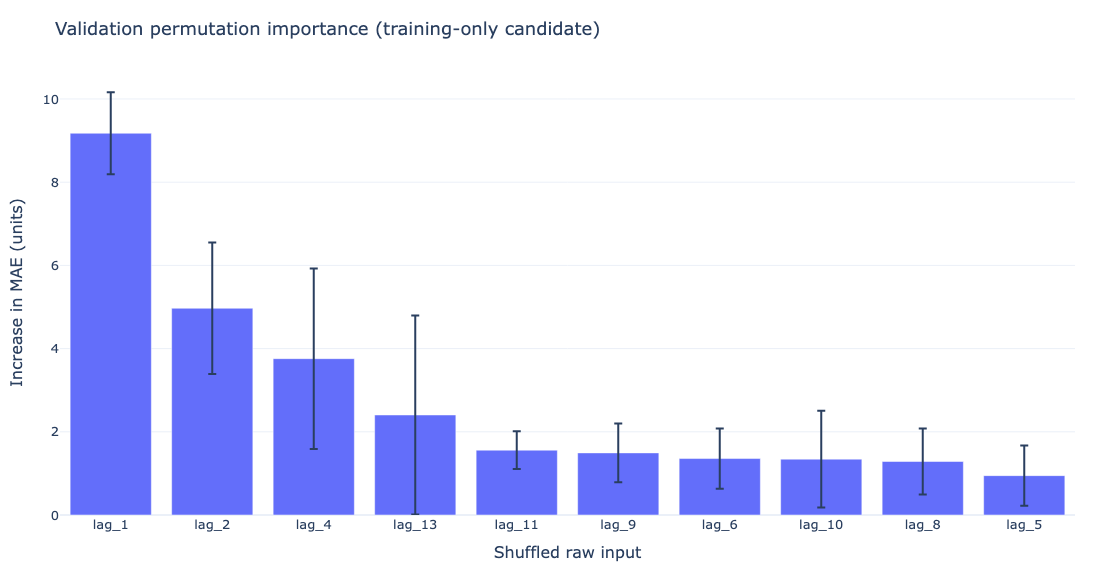

,SKU,week,lag_1,mean_13,actual_units,prediction,flat_history_prediction,lag1_plus50pct_prediction
0,16033,2011-07-25,0.0,0.00,0,20.24,20.24,20.24
1,21931,2011-06-06,114.0,217.85,230,170.22,104.35,206.73
2,84077,2011-07-18,1056.0,847.62,630,976.89,419.74,782.55


Product **16033**, week 2011-07-25: forecast **20.2 units**, versus 0 recorded. Its recent-history pattern produces a lower or equal forecast than replacing all lags with their mean (20.2). Raising only last week's units by 50% changes the prediction to 20.2; this is sensitivity, not a causal effect.

Product **21931**, week 2011-06-06: forecast **170.2 units**, versus 230 recorded. Its recent-history pattern produces a higher forecast than replacing all lags with their mean (104.3). Raising only last week's units by 50% changes the prediction to 206.7; this is sensitivity, not a causal effect.

Product **84077**, week 2011-07-18: forecast **976.9 units**, versus 630 recorded. Its recent-history pattern produces a higher forecast than replacing all lags with their mean (419.7). Raising only last week's units by 50% changes the prediction to 782.5; this is sensitivity, not a causal effect.

In [9]:
interpret_model=candidates[selected]
perm=permutation_importance(interpret_model,X_valid,y_valid,n_repeats=3,random_state=SEED,scoring='neg_mean_absolute_error',n_jobs=1)
importance=pd.DataFrame({'feature':RAW_FEATURES,'MAE_increase_units':perm.importances_mean,'std_units':perm.importances_std}).sort_values('MAE_increase_units',ascending=False)
display(importance.round(3))
show(px.bar(importance.head(10),x='feature',y='MAE_increase_units',error_y='std_units',title='Validation permutation importance (training-only candidate)',
            labels={'feature':'Shuffled raw input','MAE_increase_units':'Increase in MAE (units)'}),'feature-importance')
order=np.argsort(valid_pred);chosen=[order[0],order[len(order)//2],order[-1]]
examples=[]
for pos in chosen:
    row=X_valid.iloc[[pos]].copy()
    flat=row.copy();flat[LAGS]=row[LAGS].mean(axis=1).iloc[0]
    recent=row.copy();recent['lag_1']=row.lag_1.iloc[0]*1.5
    examples.append({'SKU':row.StockCode.iloc[0],'week':str(row.week_start.iloc[0].date()),'lag_1':row.lag_1.iloc[0],
      'mean_13':row[LAGS].mean(axis=1).iloc[0], 'actual_units':y_valid.iloc[pos], 'prediction':valid_pred[pos],
      'flat_history_prediction':interpret_model.predict(flat)[0], 'lag1_plus50pct_prediction':interpret_model.predict(recent)[0]})
display(pd.DataFrame(examples).round(2))
for ex in examples:
    direction='higher' if ex['prediction']>ex['flat_history_prediction'] else 'lower or equal'
    display(Markdown(f"Product **{ex['SKU']}**, week {ex['week']}: forecast **{ex['prediction']:.1f} units**, versus {ex['actual_units']:.0f} recorded. Its recent-history pattern produces a {direction} forecast than replacing all lags with their mean ({ex['flat_history_prediction']:.1f}). Raising only last week's units by 50% changes the prediction to {ex['lag1_plus50pct_prediction']:.1f}; this is sensitivity, not a causal effect."))


**What this means for the stakeholder.** The examples show which histories the model reacts to. A response to recent sales does not establish why customers bought, or justify changing prices.

## 10. Fairness, ethics and risks

Compare final errors by training-defined product volume tier and forecast month. These are operational reliability groups, not demographic fairness measures. Thresholds are learned from development data only. Low-volume SKUs may have lower MAE but worse proportional error; report sample counts and observed totals alongside WAPE. This selected cohort cannot establish performance for the whole catalogue or international customers.

Customer identifiers are omitted from published inputs and predictions. Open licensing permits reuse with attribution, but does not establish consent for unrelated profiling (Creative Commons, n.d.). Sparse business aggregates still need access and retention review in a real deployment. Overforecasting can misallocate purchasing attention; underforecasting can neglect fast-selling items. Human approval, group-level monitoring and fallback forecasts mitigate these risks. Bulk-order shocks, discontinued products, historical drift and missing availability cannot be repaired by model accuracy alone.



**Observed group risk.** Lower-volume products have 75.66% WAPE versus 61.81% for higher-volume products. Their error also exceeds the previous-week baseline (74.26%). Use a transparent fallback and separate monitoring for that tier; portfolio improvement must not conceal this weakness.

,dimension,group,product_weeks,actual_units,MAE_units,RMSE_units,WAPE_pct,bias_units,baseline_WAPE_pct
0,volume_tier,Higher-volume,350,156617,276.58,495.72,61.81,14.75,71.07
1,volume_tier,Lower-volume,350,46622,100.78,148.40,75.66,35.32,74.26
2,month,2011-08,50,9638,160.51,278.17,83.27,99.61,115.71
3,month,2011-09,200,56289,159.07,230.55,56.52,27.96,63.61
4,month,2011-10,250,71669,230.59,460.42,80.43,47.87,86.68
5,month,2011-11,200,65643,172.95,362.08,52.69,-25.07,56.14


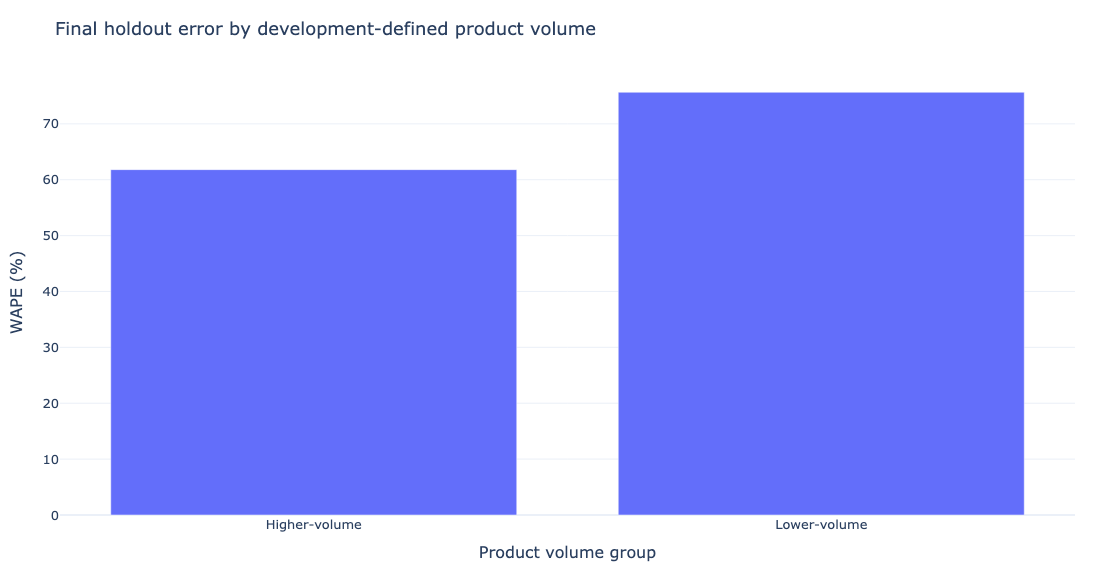

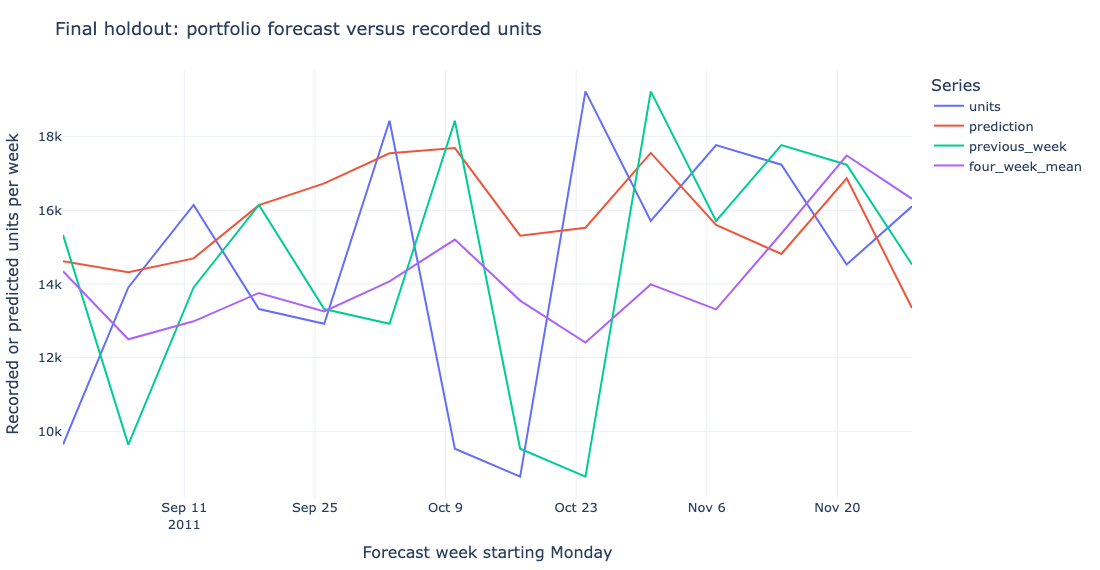

In [10]:
tier_cut=dev.groupby('StockCode').units.mean().median()
tiers=dev.groupby('StockCode').units.mean().ge(tier_cut).map({True:'Higher-volume',False:'Lower-volume'})
errors['volume_tier']=errors.StockCode.map(tiers)
errors['month']=errors.week_start.dt.strftime('%Y-%m')
group_rows=[]
for dimension in ['volume_tier','month']:
    for group,g in errors.groupby(dimension):
        group_rows.append({'dimension':dimension,'group':group,'product_weeks':len(g),'actual_units':g.units.sum(),
            **scores(g.units,g.prediction),'baseline_WAPE_pct':scores(g.units,g.previous_week)['WAPE_pct']})
group_metrics=pd.DataFrame(group_rows)
display(group_metrics.round(2))
show(px.bar(group_metrics[group_metrics.dimension.eq('volume_tier')],x='group',y='WAPE_pct',title='Final holdout error by development-defined product volume',
            labels={'group':'Product volume group','WAPE_pct':'WAPE (%)'}),'group-errors')
errors['four_week_mean']=test_baselines['Four-week mean']
trajectory=errors.groupby('week_start',as_index=False)[['units','prediction','previous_week','four_week_mean']].sum().melt(id_vars='week_start',var_name='series',value_name='weekly_units')
show(px.line(trajectory,x='week_start',y='weekly_units',color='series',title='Final holdout: portfolio forecast versus recorded units',
             labels={'week_start':'Forecast week starting Monday','weekly_units':'Recorded or predicted units per week','series':'Series'}),'test-forecast')

**What this means for the stakeholder.** Review weak groups separately and keep a human decision-maker. Product rankings must not quietly exclude smaller products simply because their forecasts are less reliable.

## 11. Recommendation

Adoption requires both the brief's 5% WAPE improvement over last week and a competitive result against the moving-average baseline. Otherwise retain the transparent rule while investigating errors. Even a passing historical comparison supports a monitored pilot, not automated purchasing. Rank products for review, attach recent error evidence and let the inventory manager approve action.

Translate performance into absolute unit-error reduction on this holdout, without equating it to units of stock saved. The bootstrap interval is exploratory: only fourteen weeks are available and adjacent weeks may remain dependent. Negative improvement is a valid outcome, not a reason to change the test window. Block 4 should add a weekly input service, unknown-SKU handling, data validation, drift and group-error monitoring, and retraining approval. Stop using forecasts when histories are incomplete, the catalogue changes, or current trading differs materially from this historical sample.



**Observed conclusion.** H1 is descriptively supported: quarterly concentration is 78.6%–81.7%. H2 ratios are 1.880 (2010) and 1.652 (2011); this supports the threshold but not a causal seasonal explanation. H3 meets its 5% point-estimate threshold, but the exploratory improvement interval is −3.08% to 18.82%, so superiority is uncertain. The four-week mean beats the model on test MAE (177.69 versus 188.68 units). Keep it as the first pilot candidate; that retrospective comparison is not proof of future savings.

In [11]:
model_wape=test_metrics.loc[selected+' tuned','WAPE_pct']
baseline_wape=test_metrics.loc[best_baseline,'WAPE_pct']
accept=bool(relative_improvement>=5 and model_wape<=baseline_wape)
recommendation='Run a monitored pilot of the tuned model' if accept else 'Keep the best transparent baseline; do not automate model-based purchasing'
unit_error_reduction=float(np.abs(y_test.to_numpy()-test_baselines['Previous week']).sum()-errors.absolute_error.sum())
summary={'selected_model':selected,'best_parameters':search.best_params_,'test_metrics':test_metrics.reset_index().to_dict('records'),
 'relative_wape_improvement_pct':relative_improvement,'absolute_unit_error_reduction':unit_error_reduction,
 'bootstrap_interval_pct':bootstrap_interval.tolist(),'best_transparent_baseline':best_baseline,'recommendation':recommendation,
 'adoption_gate_passed':accept,'cohort_size':len(cohort),'test_product_weeks':len(test),'test_first_week':str(test.week_start.min().date()),
 'test_last_week':str(test.week_start.max().date()),'folds':fold_results,'hypotheses':hypotheses.to_dict('records')}
print(recommendation)
print(f'Absolute unit-error reduction versus last week: {unit_error_reduction:,.0f} units across {len(test)} product-weeks; not an inventory saving.')
summary_lines=[f'Question: forecast next-week recorded UK sales for {len(cohort)} established products.',
 f'Model: {selected}, tuned using expanding temporal validation.',
 f'Result: {relative_improvement:.2f}% relative WAPE improvement versus last week; MAE {test_metrics.loc[selected+" tuned","MAE_units"]:.2f} units.',
 f'Action: {recommendation}.',
 'Limit: historical recorded sales omit availability, lost demand, costs and new-product behaviour.']
display(Markdown('**Executive summary (five lines)**  \n'+'  \n'.join(summary_lines)))
(RESULTS/'model-evaluation.json').write_text(json.dumps(summary,indent=2,default=str)+'\n')
errors.to_csv(RESULTS/'test-predictions.csv',index=False)
comparison.to_csv(RESULTS/'validation-comparison.csv')
pd.DataFrame(ablation).to_csv(RESULTS/'feature-ablation.csv',index=False)
group_metrics.to_csv(RESULTS/'group-errors.csv',index=False)

Keep the best transparent baseline; do not automate model-based purchasing
Absolute unit-error reduction versus last week: 13,862 units across 700 product-weeks; not an inventory saving.


**Executive summary (five lines)**  
Question: forecast next-week recorded UK sales for 50 established products.  
Model: Boosting, tuned using expanding temporal validation.  
Result: 9.50% relative WAPE improvement versus last week; MAE 188.68 units.  
Action: Keep the best transparent baseline; do not automate model-based purchasing.  
Limit: historical recorded sales omit availability, lost demand, costs and new-product behaviour.

**What this means for the stakeholder.** Choose the simplest method supported by evidence. The business still needs a prospective pilot and operational stock information to establish actual savings.

## 12. Saving the model

Save the development-fitted pipeline without retraining on the holdout. The artifact contains feature derivation, preprocessing and the fitted estimator. Reload it and check one forecast against the original prediction. Keep `retail_features.py`, the input schema and matching library versions with it; retraining is safer than loading a pickle from an untrusted source. A future deployment may retrain after evaluation, but that is a separate version, not this tested artifact.

In [12]:
artifact=BASE/'model.joblib'
joblib.dump(final_model,artifact,compress=3)
loaded=joblib.load(artifact)
np.testing.assert_allclose(loaded.predict(X_test.iloc[[0]]),test_predictions[:1],rtol=1e-12,atol=1e-12)
assert artifact.stat().st_size<50_000_000
schema={'required_columns':RAW_FEATURES,'moment':'Monday after prior week closes','horizon':'next Monday-Sunday',
        'scope':'UK fixed cohort; units of recorded sales','cohort':cohort,'lags':'lag_1 is previous closed week; lag_13 is thirteen weeks ago',
        'feature_module':'retail_features.py','test_not_used_for_fit':True}
(BASE/'model-input-schema.json').write_text(json.dumps(schema,indent=2)+'\n')
versions={'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'scikit-learn':sklearn.__version__,
          'plotly':plotly.__version__,'joblib':joblib.__version__}
summary['versions']=versions;summary['runtime_seconds']=time.perf_counter()-START
(RESULTS/'model-evaluation.json').write_text(json.dumps(summary,indent=2,default=str)+'\n')
display(pd.Series(versions,name='Execution versions'))
print(f'Model saved and reload verified: {artifact.name}, {artifact.stat().st_size:,} bytes')
print(f'Notebook execution: {summary["runtime_seconds"]:.1f} seconds')
assert summary['runtime_seconds']<600, 'Runtime exceeds the deliverable limit'

python          3.12.14
pandas            3.1.1
numpy             2.5.4
scikit-learn      1.9.1
plotly            6.9.0
joblib            1.6.0
Name: Execution versions, dtype: str

Model saved and reload verified: model.joblib, 58,898 bytes
Notebook execution: 6.4 seconds


**What this means for the stakeholder.** The saved object reproduces the evaluated model. Its input is a closed-week history row; it is not a live connection to stock or transaction systems.

## 13. References

Chen, D. (2012). *Online Retail II* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D

Creative Commons. (n.d.). *Attribution 4.0 International (CC BY 4.0).* https://creativecommons.org/licenses/by/4.0/

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/toolbox.html

scikit-learn developers. (n.d.-a). *Pipelines and composite estimators.* https://scikit-learn.org/stable/modules/compose.html

scikit-learn developers. (n.d.-b). *TimeSeriesSplit.* https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

scikit-learn developers. (n.d.-c). *Permutation feature importance.* https://scikit-learn.org/stable/modules/permutation_importance.html